<a href="https://colab.research.google.com/github/efitznm/Data-Science-Portfolio-C22/blob/main/Modules/Module_4_Tree_Based_Methods/Projects/Instructions/Project.4-Spotify/Spotify_Pass_08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Data Collection/Sources


### Load Modules

In [1]:
# Load Pandas, Numpy, and Matplotlib modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import datasets, metrics, model_selection
from sklearn import model_selection
from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeRegressor
from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_squared_error
from sklearn.metrics import accuracy_score

import requests

from google.colab import userdata
import os

### Authenticate to Hugging Face


In [2]:
# Retrieve the token from Colab's secret manager
os.environ["HF_TOKEN"] = userdata.get('hf_token')
_ = os.environ["HF_TOKEN"]
f"{_[:5]} ... {_[-3:]}"

'hf_as ... mJe'

In [3]:
os.environ["HF_ACCOUNT"] = userdata.get('hf_account')
hf_account = os.environ["HF_ACCOUNT"]
hf_account


'ericbdf7'

In [4]:
hf_repo = "Data_Science-22"
os.environ["HF_REPO"] = hf_repo
hf_repo


'Data_Science-22'

In [5]:
# Log in automatically without an interactive prompt
! hf auth login --token $HF_TOKEN


Hint: A new version of huggingface_hub (2.4.0) is available! You are using version 1.33.0.
To update, run: hf update
Hint: The `hf-cli` skill is not installed. Run `hf skills add -g` to teach your AI agents how to use the `hf` CLI.
The token has not been saved to the git credentials helper. Pass `add_to_git_credential=True` in this function directly or `--add-to-git-credential` if using via `hf`CLI if you want to set the git credential as well.
Token is valid (permission: fineGrained).
The token `colab` has been saved to /root/.cache/huggingface/stored_tokens
Your token has been saved to /root/.cache/huggingface/token
Login successful.
Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


### Read parquet from Hugging Face


In [6]:
# Construct the base Hugging Face URL for your dataset files
hf_url = f"https://huggingface.co/datasets/{hf_account}/{hf_repo}/resolve/main/spotify.parquet"
hf_url


'https://huggingface.co/datasets/ericbdf7/Data_Science-22/resolve/main/spotify.parquet'

In [7]:
df3 = pd.read_parquet( hf_url )
df3.shape


(1556, 20)

In [8]:
df3.iloc[:,:5].info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1556 entries, 0 to 1555
Data columns (total 5 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   Popularity                 1556 non-null   object
 1   Highest Charting Position  1556 non-null   int64 
 2   Number of Times Charted    1556 non-null   int64 
 3   Week of Highest Charting   1556 non-null   object
 4   Streams                    1556 non-null   object
dtypes: int64(2), object(3)
memory usage: 60.9+ KB


In [9]:
X_features = df3.drop(columns=['Popularity']).copy()
X_features

,Highest Charting Position,Number of Times Charted,Week of Highest Charting,Streams,Artist,Artist Followers,Genre,Release Date,Weeks Charted,Danceability,Energy,Loudness,Speechiness,Acousticness,Liveness,Tempo,Duration (ms),Valence,Chord
0,1,8,2021-07-23--2021-07-30,"48,633,449",Måneskin,3377762,"['indie rock italiano', 'italian pop']",2017-12-08,2021-07-23--2021-07-30\n2021-07-16--2021-07-23...,0.714,0.8,-4.808,0.0504,0.127,0.359,134.002,211560,0.589,B
1,2,3,2021-07-23--2021-07-30,"47,248,719",The Kid LAROI,2230022,['australian hip hop'],2021-07-09,2021-07-23--2021-07-30\n2021-07-16--2021-07-23...,0.591,0.764,-5.484,0.0483,0.0383,0.103,169.928,141806,0.478,C#/Db
2,1,11,2021-06-25--2021-07-02,"40,162,559",Olivia Rodrigo,6266514,['pop'],2021-05-21,2021-07-23--2021-07-30\n2021-07-16--2021-07-23...,0.563,0.664,-5.044,0.154,0.335,0.0849,166.928,178147,0.688,A
3,3,5,2021-07-02--2021-07-09,"37,799,456",Ed Sheeran,83293380,"['pop', 'uk pop']",2021-06-25,2021-07-23--2021-07-30\n2021-07-16--2021-07-23...,0.808,0.897,-3.712,0.0348,0.0469,0.364,126.026,231041,0.591,B
4,5,1,2021-07-23--2021-07-30,"33,948,454",Lil Nas X,5473565,"['lgbtq+ hip hop', 'pop rap']",2021-07-23,2021-07-23--2021-07-30,0.736,0.704,-7.409,0.0615,0.0203,0.0501,149.995,212000,0.894,D#/Eb
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1551,195,1,2019-12-27--2020-01-03,"4,630,675",Dua Lipa,27167675,"['dance pop', 'pop', 'uk pop']",2017-06-02,2019-12-27--2020-01-03,0.762,0.7,-6.021,0.0694,0.00261,0.153,116.073,209320,0.608,A
1552,196,1,2019-12-27--2020-01-03,"4,623,030",Jorge & Mateus,15019109,"['sertanejo', 'sertanejo universitario']",2019-10-11,2019-12-27--2020-01-03,0.528,0.87,-3.123,0.0851,0.24,0.333,152.37,181930,0.714,B
1553,197,1,2019-12-27--2020-01-03,"4,620,876",Camila Cabello,22698747,"['dance pop', 'electropop', 'pop', 'post-teen ...",2018-01-12,2019-12-27--2020-01-03,0.765,0.523,-4.333,0.03,0.184,0.132,104.988,217307,0.394,D
1554,198,1,2019-12-27--2020-01-03,"4,607,385","Dadá Boladão, Tati Zaqui, OIK",208630,"['brega funk', 'funk carioca']",2019-09-25,2019-12-27--2020-01-03,0.832,0.55,-7.026,0.0587,0.249,0.182,154.064,152784,0.881,F


In [10]:
y_target = df3['Popularity'].copy()
y_target

,Popularity
0,100
1,99
2,99
3,98
4,96
...,...
1551,79
1552,66
1553,81
1554,60


### Backup

In [11]:
df_clean = df3.copy()

## Feature Selection

In [ ]:
# 1. Select target and chosen features
cols = ['Popularity', 'Danceability', 'Energy', 'Tempo', 'Streams']
df_rf = df_clean[cols].copy()

# 2. Strip commas from Streams and convert all 5 columns to numeric
df_rf['Streams'] = df_rf['Streams'].astype(str).str.replace(',', '', regex=False)
for col in cols:
    df_rf[col] = pd.to_numeric(df_rf[col], errors='coerce')

# 3. Drop rows with missing values
df_rf = df_rf.dropna().reset_index(drop=True)

# 4. Define features and target for the Random Forest sections
X_features = df_rf[['Danceability', 'Energy', 'Tempo', 'Streams']]
y_target = df_rf['Popularity']

# Random Forest Regression

### Max Depth = 3

In [ ]:
numLoops = 10
rmse_scores = np.zeros(numLoops)

for idx in range(numLoops):
    X_train, X_test, y_train, y_test = train_test_split(
        X_features, y_target, test_size=0.2, random_state=idx
    )
    model = RandomForestRegressor(max_depth=3, n_jobs=-1, random_state=idx)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    rmse_scores[idx] = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"Mean CV RMSE: {rmse_scores.mean():.4f}")

Mean CV RMSPE: 0.2456


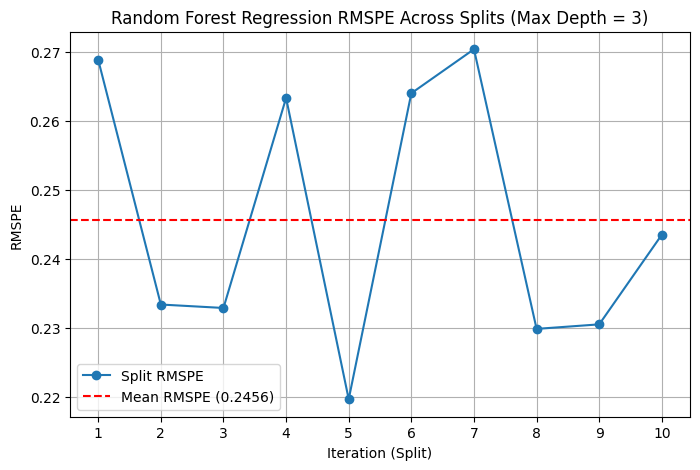

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, numLoops + 1), rmse_scores, marker='o', label='Split RMSE')
plt.axhline(rmse_scores.mean(), color='red', linestyle='--', label=f'Mean RMSE ({rmse_scores.mean():.4f})')
plt.xlabel('Iteration (Split)')
plt.ylabel('RMSE')
plt.title('Random Forest Regression RMSE Across Splits (Max Depth = 3)')
plt.xticks(range(1, numLoops + 1))
plt.legend()
plt.grid(True)
plt.show()

### Choose Max Depth

In [ ]:
max_depths = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
rmse_depth = np.zeros(len(max_depths))
std_depth = np.zeros(len(max_depths))

numLoops = 10
for n, depth in enumerate(max_depths):
    rmse_scores = np.zeros(numLoops)
    for idx in range(0, numLoops):
        X_train, X_test, y_train, y_test = train_test_split(
            X_features, y_target, test_size=0.2, random_state=idx
        )
        model = RandomForestRegressor(max_depth=depth, n_jobs=-1, random_state=idx)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        rmse_scores[idx] = np.sqrt(mean_squared_error(y_test, y_pred))
    rmse_depth[n] = rmse_scores.mean()
    std_depth[n] = rmse_scores.std(ddof=1)

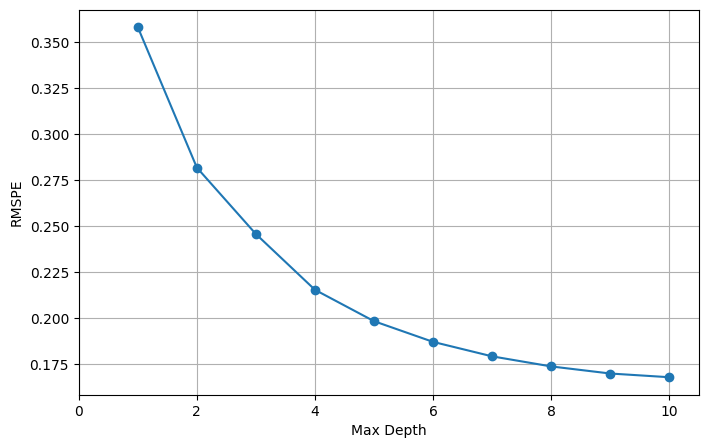

In [ ]:
# Plot the result
plt.figure(figsize=(8, 5))
plt.plot(max_depths, rmse_depth, marker='o')
plt.xlabel('Max Depth')
plt.ylabel('RMSE')
plt.title('Random Forest Mean CV RMSE by Max Depth')
plt.xlim(0, 10.5)
plt.grid()
plt.show()

In [ ]:
# Display the best depth value
best_depth = max_depths[np.argmin(rmse_depth)]
print(f"Best Max Depth: {best_depth} (RMSE: {rmse_depth.min():.4f})")

Best Max Depth: 10 (RMSPE: 0.1677)


### Max Depth = Chosen

In [ ]:
numLoops = 10
rmse_scores = np.zeros(numLoops)

for idx in range(numLoops):
    X_train, X_test, y_train, y_test = train_test_split(
        X_features, y_target, test_size=0.2, random_state=idx
    )
    model = RandomForestRegressor(max_depth=best_depth, n_jobs=-1, random_state=idx)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    rmse_scores[idx] = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"Mean CV RMSE: {rmse_scores.mean():.4f}")

Mean CV RMSPE: 0.1677


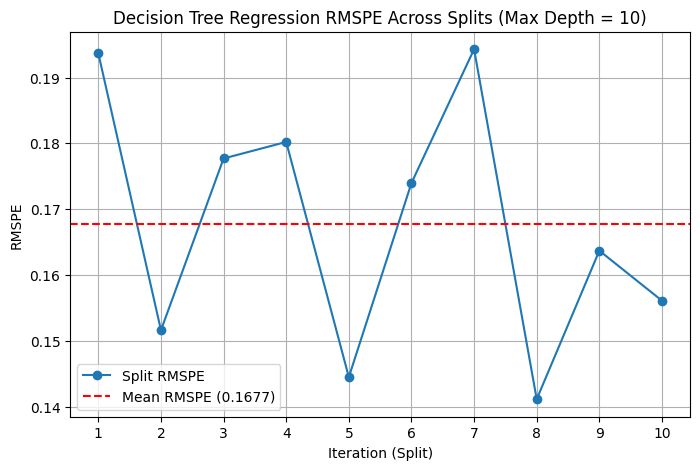

In [ ]:
# Plot the result
plt.figure(figsize=(8, 5))
plt.plot(range(1, numLoops + 1), rmse_scores, marker='o', label='Split RMSE')
plt.axhline(rmse_scores.mean(), color='red', linestyle='--', label=f'Mean RMSE ({rmse_scores.mean():.4f})')
plt.xlabel('Iteration (Split)')
plt.ylabel('RMSE')
plt.title(f'Random Forest Regression RMSE Across Splits (Max Depth = {best_depth})')
plt.xticks(range(1, numLoops + 1))
plt.legend()
plt.grid(True)
plt.show()

# Visualize the Decision Tree

In [ ]:
import graphviz
from IPython.display import display
from sklearn import tree

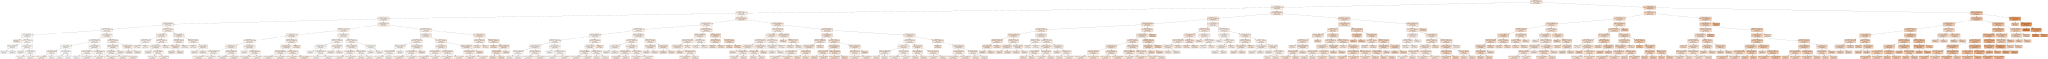

In [ ]:
# Option 1
display(
  graphviz.Source(
    tree.export_graphviz(
      model.estimators_[0],
      feature_names = X_features.columns,
      filled = True,
    )
  )
)

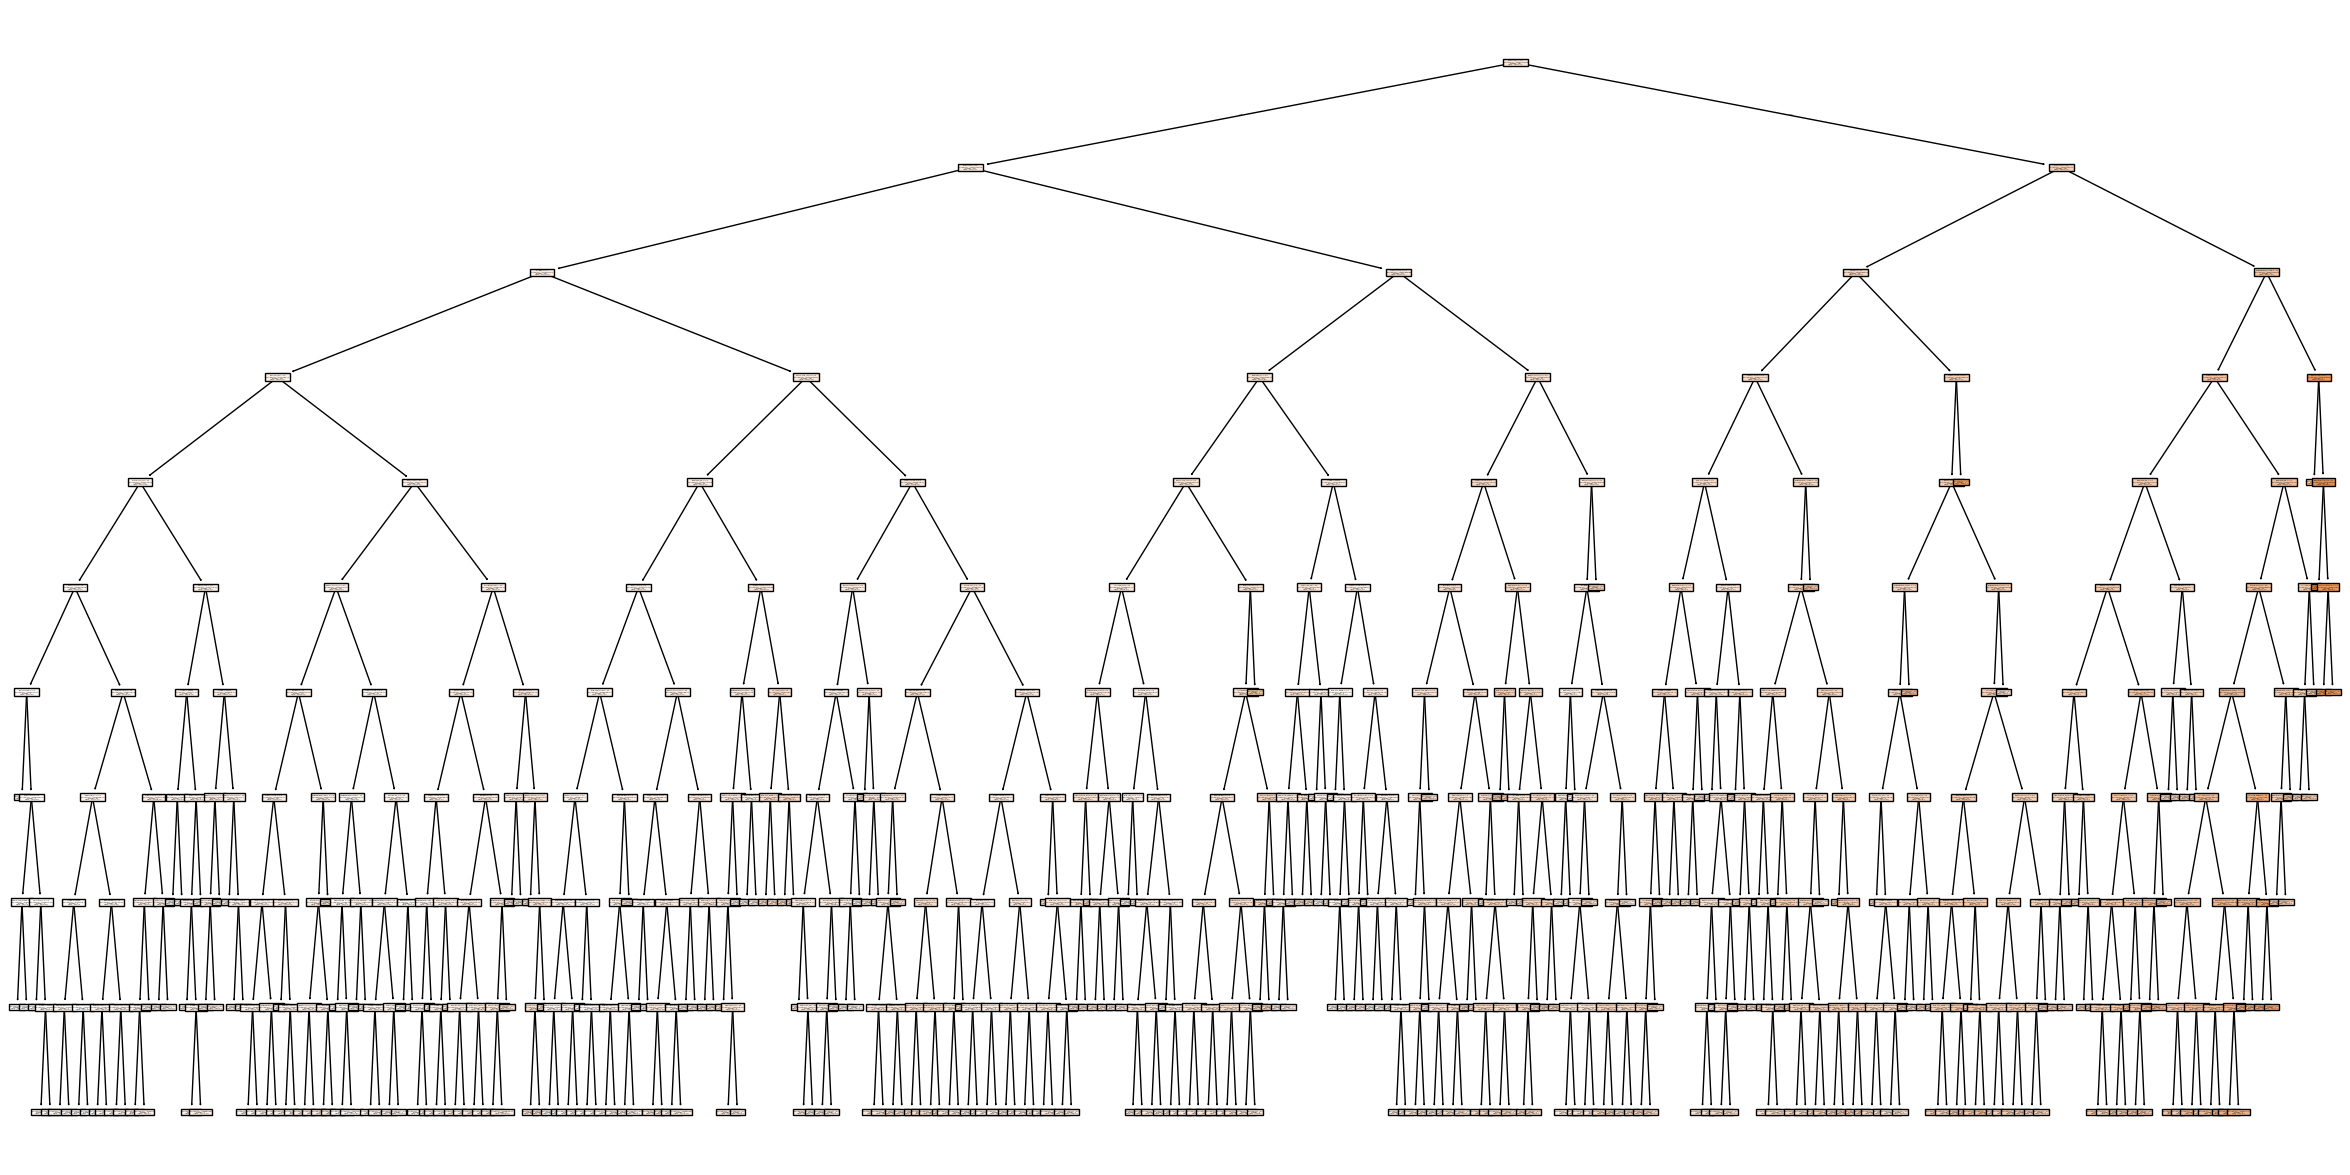

In [ ]:
# Option 2
plt.figure(figsize=(30, 15))
tree_plot = tree.plot_tree(
  model.estimators_[0],
  feature_names = X_features.columns,
  filled = True,
)


## Find Important Predictors

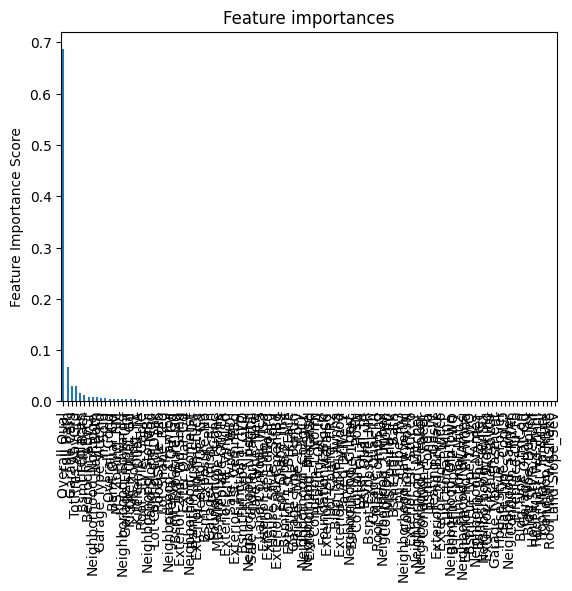

In [ ]:
importances = model.feature_importances_
tree_importances = pd.Series( importances, index = X_features.columns )

plt.figure()
# tree_importances.plot.bar()
tree_importances.sort_values( ascending = False ).plot.bar()
plt.title("Feature importances")
plt.ylabel('Feature Importance Score') ;


In [ ]:
( tree_importances.sort_values( ascending = False ) * 100 ).cumsum()


,0
Overall Qual,68.643988
Full Bath,75.281961
Garage Cars,78.238014
TotRms AbvGrd,81.153358
Fireplaces,82.822218
...,...
Roof Matl_WdShngl,99.991327
Roof Matl_Tar&Grv,99.995027
Condition 1_RRAe,99.998343
Roof Matl_WdShake,99.999798
